<a href="https://colab.research.google.com/github/martalombardi/rhetorical_signatures/blob/main/explore_raid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install huggingface_hub
!pip install -q spacy pandas numpy tqdm
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 23.6 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [3]:

from pathlib import Path
import sys
import pandas as pd

ROOT = Path("/content/rhetorical_signatures")
CODE_DIR = ROOT / "code"
PROCESSING_DIR = CODE_DIR / "01_data_processing"

sys.path.insert(0, str(CODE_DIR))

from config import (
    TRAIN_FILE,
    RAW_DIR,
    FILTERED_DIR,
    RESULTS_DIR,
    RANDOM_SEED,
)

print("Project:", ROOT)
print("Training file:", TRAIN_FILE)
print("Dataset exists:", TRAIN_FILE.exists())

Project: /content/rhetorical_signatures
Training file: /content/rhetorical_signatures/data/raw/raid/train.csv
Dataset exists: True


In [4]:

import subprocess

download_script = PROCESSING_DIR / "01_download_raid.py"

if not TRAIN_FILE.exists():
    subprocess.run(
        [sys.executable, str(download_script)],
        cwd=ROOT,
        check=True,
    )
else:
    print("RAID dataset already downloaded.")

print("Training file:", TRAIN_FILE)
print("Size (GB):", round(TRAIN_FILE.stat().st_size / 1024**3, 2))

RAID dataset already downloaded.
Training file: /content/rhetorical_signatures/data/raw/raid/train.csv
Size (GB): 10.97


In [5]:
sample = pd.read_csv(TRAIN_FILE, nrows=1000)

print("Columns:")
print(sample.columns.tolist())

display(sample.head(3))

for col in ["domain", "model", "prompting", "decoding", "attack", "repetition_penalty"]:
    if col in sample.columns:
        print(f"\n{col}:")
        display(sample[col].value_counts(dropna=False))


Columns:
['id', 'adv_source_id', 'source_id', 'model', 'decoding', 'repetition_penalty', 'attack', 'domain', 'title', 'prompt', 'generation']


,id,adv_source_id,source_id,model,decoding,repetition_penalty,attack,domain,title,prompt,generation
0,e5e058ce-be2b-459d-af36-32532aaba5ff,e5e058ce-be2b-459d-af36-32532aaba5ff,e5e058ce-be2b-459d-af36-32532aaba5ff,human,NaN,NaN,none,abstracts,FUTURE-AI: Guiding Principles and Consensus Re...,NaN,The recent advancements in artificial intellig...
1,f95b107b-d176-4af5-90f7-4d0bb20caf93,f95b107b-d176-4af5-90f7-4d0bb20caf93,f95b107b-d176-4af5-90f7-4d0bb20caf93,human,NaN,NaN,none,abstracts,EdgeFlow: Achieving Practical Interactive Segm...,NaN,High-quality training data play a key role in ...
2,856d8972-9e3d-4544-babc-0fe16f21e04d,856d8972-9e3d-4544-babc-0fe16f21e04d,856d8972-9e3d-4544-babc-0fe16f21e04d,human,NaN,NaN,none,abstracts,Semi-supervised Contrastive Learning for Label...,NaN,The success of deep learning methods in medica...



domain:


,count
domain,
abstracts,1000



model:


,count
model,
llama-chat,507
human,493


... (2 outputs left out)


attack:


,count
attack,
none,1000



repetition_penalty:


,count
repetition_penalty,
NaN,493
no,254
yes,253


In [6]:

import importlib.util

module_path = PROCESSING_DIR / "02_process_sentences.py"

spec = importlib.util.spec_from_file_location(
    "process_sentences",
    module_path,
)

process_sentences = importlib.util.module_from_spec(spec)
spec.loader.exec_module(process_sentences)

print("Module loaded successfully.")


Module loaded successfully.


In [7]:

documents, sentences = process_sentences.analyze_sentence_lengths(
    domain="abstracts",
    prompting=None,
    attack="null",
    decoding="greedy",
    repetition_penalty="no",
    save=True,
    show_progress=True,
)

print("Documents:", len(documents))
print("Sentences:", len(sentences))

display(documents.head())
display(sentences.head())


RAID sentence parsing: 0docs [00:00, ?docs/s]

Saved sentence analysis: /content/rhetorical_signatures/results/sentences_report/domain-abstracts__prompting-all__attack-null__decoding-greedy__rep-no
Documents: 12362
Sentences: 93427


,id,source_id,source,n_sentences,n_words
0,e5e058ce-be2b-459d-af36-32532aaba5ff,e5e058ce-be2b-459d-af36-32532aaba5ff,Human,6,206
1,f95b107b-d176-4af5-90f7-4d0bb20caf93,f95b107b-d176-4af5-90f7-4d0bb20caf93,Human,9,137
2,856d8972-9e3d-4544-babc-0fe16f21e04d,856d8972-9e3d-4544-babc-0fe16f21e04d,Human,9,213
3,fbc8a5ea-90fa-47b8-8fa7-73dd954f1524,fbc8a5ea-90fa-47b8-8fa7-73dd954f1524,Human,10,271
4,72c41b8d-0069-4886-b734-a4000ffca286,72c41b8d-0069-4886-b734-a4000ffca286,Human,10,232


,id,sentence_idx,n_words,sentence_text
0,e5e058ce-be2b-459d-af36-32532aaba5ff,1,47,The recent advancements in artificial intellig...
1,e5e058ce-be2b-459d-af36-32532aaba5ff,2,43,Notwithstanding the successes and\nfuture pote...
2,e5e058ce-be2b-459d-af36-32532aaba5ff,3,28,"Despite these concerns and risks, there are\nc..."
3,e5e058ce-be2b-459d-af36-32532aaba5ff,4,32,"To bridge this gap, this paper introduces a ca..."
4,e5e058ce-be2b-459d-af36-32532aaba5ff,5,25,These\nguiding principles are named FUTURE-AI ...


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# Associate each sentence with its source
sentence_stats = sentences.merge(
    documents[["id", "source"]],
    on="id",
    how="left",
    validate="many_to_one"
)

print(f"Documents analyzed: {len(documents):,}")
print(f"Sentences analyzed: {len(sentences):,}")

if "selected" in globals():
    print(f"Documents selected: {len(selected):,}")

Documents analyzed: 12,362
Sentences analyzed: 93,427


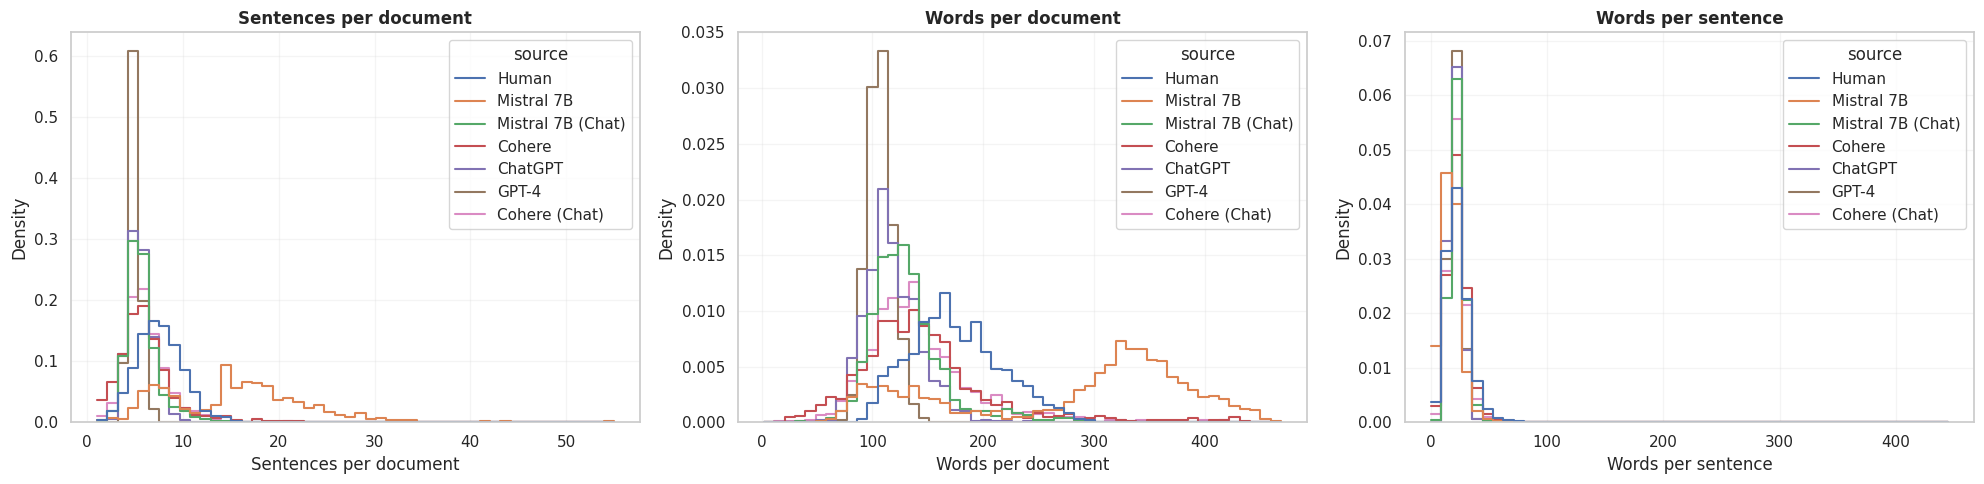

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

plots = [
    (documents, "n_sentences", "Sentences per document"),
    (documents, "n_words", "Words per document"),
    (sentence_stats, "n_words", "Words per sentence"),
]

for ax, (df, col, title) in zip(axes, plots):
    sns.histplot(
        data=df,
        x=col,
        hue="source",
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        bins=50,
        ax=ax,
    )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel(title)
    ax.set_ylabel("Density")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [15]:

import sys
import importlib.util
from pathlib import Path

import pandas as pd
from IPython.display import display

# ============================================================
# 1. RELOAD MODULE
# ============================================================

ROOT = Path("/content/rhetorical_signatures")
CODE_DIR = ROOT / "code"
MODULE_PATH = CODE_DIR / "01_data_processing" / "02_process_sentences.py"

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

if not MODULE_PATH.exists():
    raise FileNotFoundError(f"Module not found: {MODULE_PATH}")

module_name = "process_sentences"
spec = importlib.util.spec_from_file_location(module_name, MODULE_PATH)
process_sentences = importlib.util.module_from_spec(spec)
sys.modules[module_name] = process_sentences
spec.loader.exec_module(process_sentences)

print(f"Module loaded: {process_sentences.__file__}")

# ============================================================
# 2. COMMON PARAMETERS
# ============================================================

params = dict(
    documents=documents,
    sentences=sentences,
    min_sentences=6,
    max_sentences=10,
    domain="abstracts",
    prompting=None,
    attack="null",
    decoding="greedy",
    repetition_penalty="no",
    sampling="common_bins",
    n_bins=10,
    seed=42,
    include_human=True,
    save=False,
)

# ============================================================
# 3. MATCHED DATASET
#    Same source_id across all sources
# ============================================================

print("\nRunning MATCHED selection...")

selected_matched, comparison_matched = (
    process_sentences.select_sentence_dataset(
        **params,
        match_source_id=True,
    )
)

# ============================================================
# 4. UNMATCHED DATASET
#    Independent sampling per source
# ============================================================

print("\nRunning UNMATCHED selection...")

selected_unmatched, comparison_unmatched = (
    process_sentences.select_sentence_dataset(
        **params,
        match_source_id=False,
    )
)

# ============================================================
# 5. THRESHOLD COMPARISON
# ============================================================

print("\n=== MATCHED: SENTENCE THRESHOLDS ===")
display(comparison_matched)

print("\n=== UNMATCHED: SENTENCE THRESHOLDS ===")
display(comparison_unmatched)

# ============================================================
# 6. DOCUMENT COUNTS PER SOURCE
# ============================================================

counts = pd.concat(
    [
        selected_matched.groupby("source").size().rename("Matched"),
        selected_unmatched.groupby("source").size().rename("Unmatched"),
    ],
    axis=1,
).fillna(0).astype(int)

print("\n=== DOCUMENTS PER SOURCE ===")
display(counts)

# ============================================================
# 7. LENGTH STATISTICS
# ============================================================

summary = pd.concat(
    [
        selected_matched.assign(dataset="Matched"),
        selected_unmatched.assign(dataset="Unmatched"),
    ],
    ignore_index=True,
)

length_stats = (
    summary.groupby(["dataset", "source"])["first_n_words"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

print("\n=== WORD COUNT STATISTICS ===")
display(length_stats)

# ============================================================
# 8. FINAL SUMMARY
# ============================================================

matched_n = selected_matched.attrs["raid_metadata"]["best_n_sentences"]
unmatched_n = selected_unmatched.attrs["raid_metadata"]["best_n_sentences"]

print("\n=== FINAL SUMMARY ===")
print(f"Matched   | Best sentences: {matched_n} | Documents: {len(selected_matched):,}")
print(f"Unmatched | Best sentences: {unmatched_n} | Documents: {len(selected_unmatched):,}")
print("\nNo files saved (save=False).")


Module loaded: /content/rhetorical_signatures/code/01_data_processing/02_process_sentences.py

Running MATCHED selection...
Best n=6; minimum selected LLM documents=76

Running UNMATCHED selection...
Best n=6; minimum selected LLM documents=386

=== MATCHED: SENTENCE THRESHOLDS ===


,n_sentences,min_eligible_llm,eligible_Human,eligible_ChatGPT,eligible_GPT-4,eligible_Mistral 7B,eligible_Mistral 7B (Chat),eligible_Cohere,eligible_Cohere (Chat),min_selected_llm,total_selected,status,selected_Human,selected_ChatGPT,selected_GPT-4,selected_Mistral 7B,selected_Mistral 7B (Chat),selected_Cohere,selected_Cohere (Chat),is_best
0,6,421,1465,947,421,1690,956,1022,1091,76,532,ok,76,76,76,76,76,76,76,True
1,7,44,1189,410,44,1591,431,658,676,0,0,No complete source_id groups,0,0,0,0,0,0,0,False
2,8,2,873,144,2,1476,199,398,400,0,0,No complete source_id groups,0,0,0,0,0,0,0,False
3,9,0,574,37,0,1368,113,236,230,0,0,At least one requested source has no eligible ...,0,0,0,0,0,0,0,False
4,10,0,332,10,0,1287,66,159,140,0,0,At least one requested source has no eligible ...,0,0,0,0,0,0,0,False



=== UNMATCHED: SENTENCE THRESHOLDS ===


,n_sentences,min_eligible_llm,eligible_Human,eligible_ChatGPT,eligible_GPT-4,eligible_Mistral 7B,eligible_Mistral 7B (Chat),eligible_Cohere,eligible_Cohere (Chat),min_selected_llm,total_selected,status,selected_Human,selected_ChatGPT,selected_GPT-4,selected_Mistral 7B,selected_Mistral 7B (Chat),selected_Cohere,selected_Cohere (Chat),is_best
0,6,421,1465,947,421,1690,956,1022,1091,386,2702,ok,386,386,386,386,386,386,386,True
1,7,44,1189,410,44,1591,431,658,676,44,308,ok,44,44,44,44,44,44,44,False
2,8,2,873,144,2,1476,199,398,400,2,14,ok,2,2,2,2,2,2,2,False
3,9,0,574,37,0,1368,113,236,230,0,0,At least one requested source has no eligible ...,0,0,0,0,0,0,0,False
4,10,0,332,10,0,1287,66,159,140,0,0,At least one requested source has no eligible ...,0,0,0,0,0,0,0,False



=== DOCUMENTS PER SOURCE ===


,Matched,Unmatched
source,,
ChatGPT,76,386
Cohere,76,386
Cohere (Chat),76,386
GPT-4,76,386
Human,76,386
Mistral 7B,76,386
Mistral 7B (Chat),76,386



=== WORD COUNT STATISTICS ===


count    mean  median    std  min  max
dataset   source                                                   
Matched   ChatGPT               76  117.36   115.5  11.76   95  159
          Cohere                76  127.03   120.0  24.09   76  218
          Cohere (Chat)         76  126.05   127.0  16.98   79  155
          GPT-4                 76  116.96   116.5  11.05   88  136
          Human                 76  132.79   124.5  30.66   77  200
          Mistral 7B            76  101.80    99.0  24.11   63  202
          Mistral 7B (Chat)     76  126.09   125.5  15.04   99  162
Unmatched ChatGPT              386  116.50   117.0  10.39   84  145
          Cohere               386  116.49   117.0  11.00   59  155
          Cohere (Chat)        386  116.59   117.0  10.70   91  152
          GPT-4                386  116.48   117.0  10.18   89  148
          Human                386  116.58   117.0  10.63   79  148
          Mistral 7B           386  116.09   117.0  11.99   38  147
          Mistral 7B (Chat)    386  116.43   117.0  10.42   78  145


=== FINAL SUMMARY ===
Matched   | Best sentences: 6 | Documents: 532
Unmatched | Best sentences: 6 | Documents: 2,702

No files saved (save=False).
